Fashion mnist : CNN vs Random Forest

1. Seting up and getting the data

In [2]:
import time
import numpy as np
import tensorflow as tf

random_seed = 40
pixelCount = 255.0
tf.keras.utils.set_random_seed(random_seed)
class_name = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Hills", "shirt", "sneaker", "bag", "boot" ]

fashionmnst = tf.keras.datasets.fashion_mnist;
(trainImages, trainLabels), (test_images, test_labels) = fashionmnst.load_data()
trainImages = trainImages/pixelCount;
test_images = test_images/pixelCount;
print(f"trainng img shape is : {trainImages.shape}")
print(f"Text img shapes : {test_images.shape}")

trainng img shape is : (60000, 28, 28)
Text img shapes : (10000, 28, 28)


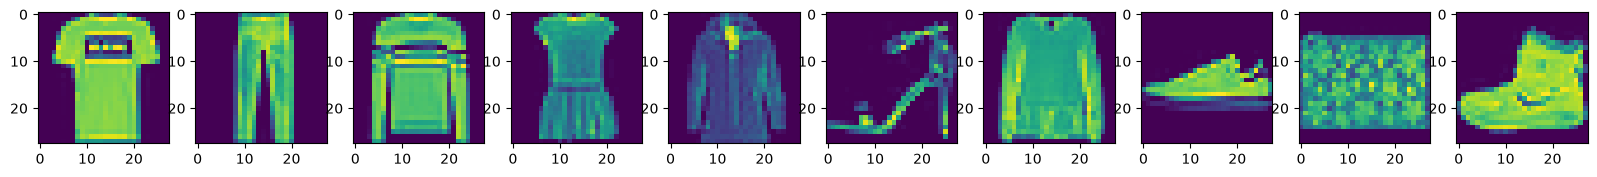

In [3]:
import matplotlib.pyplot as matplotplt

matplotplt.figure(figsize=(20,5))
for label in range(10):
    # trying to find the first img with this label.
    trainingLabelSizes = len(trainLabels);
    for i in range(trainingLabelSizes):
        if(trainLabels[i] == label ):
            firstImg = trainImages[i]
            break; # found it no reason to loop

    matplotplt.subplot(1,10, label+1)
    matplotplt.imshow(firstImg)
    lables = class_name[label]
    # matplotplt.title(lables)

matplotplt.show()

2. Training the cnn

In [ ]:
lenTrainImages = len(trainImages)
lenTestImages = len(test_images)
pixel_width = 28
pixel_height = 28
cnnTrainImgs = trainImages.reshape(lenTrainImages, pixel_width,pixel_height,1)
cnnTestImgs = test_images.reshape(lenTestImages, pixel_width,pixel_height,1)

# sequential because the layers run sequentially one, after another
cnn = tf.keras.Sequential()

# now input layer
cnn.add(tf.keras.layers.Input(shape=(pixel_width, pixel_height, 1)))

# 32 small, 3 by 3 filters that tryies to find simple patters
cnn.add(tf.keras.layers.Conv2D(32,3,activation="relu"))

# shrinks the image by half
cnn.add(tf.keras.layers.MaxPooling2D())

# second layer
filter_sizes = 64 # the higher the number the slower but will learn better patterns.
cnn.add(tf.keras.layers.Conv2D(filter_sizes,3,activation="relu"))

# shirking it again, traing is faster when shrinked.
# cnn.add(tf.keras.layers.MaxPooling2D())

cnn.add(tf.keras.layers.Flatten())

cnn.add(tf.keras.layers.Dense(128, activation="relu"))
cnn.add(tf.keras.layers.Dense(10, activation="softmax"))

cnn.compile(
    optimizer="adam",                          
    loss="sparse_categorical_crossentropy",   
    metrics=["accuracy"],                     
)
